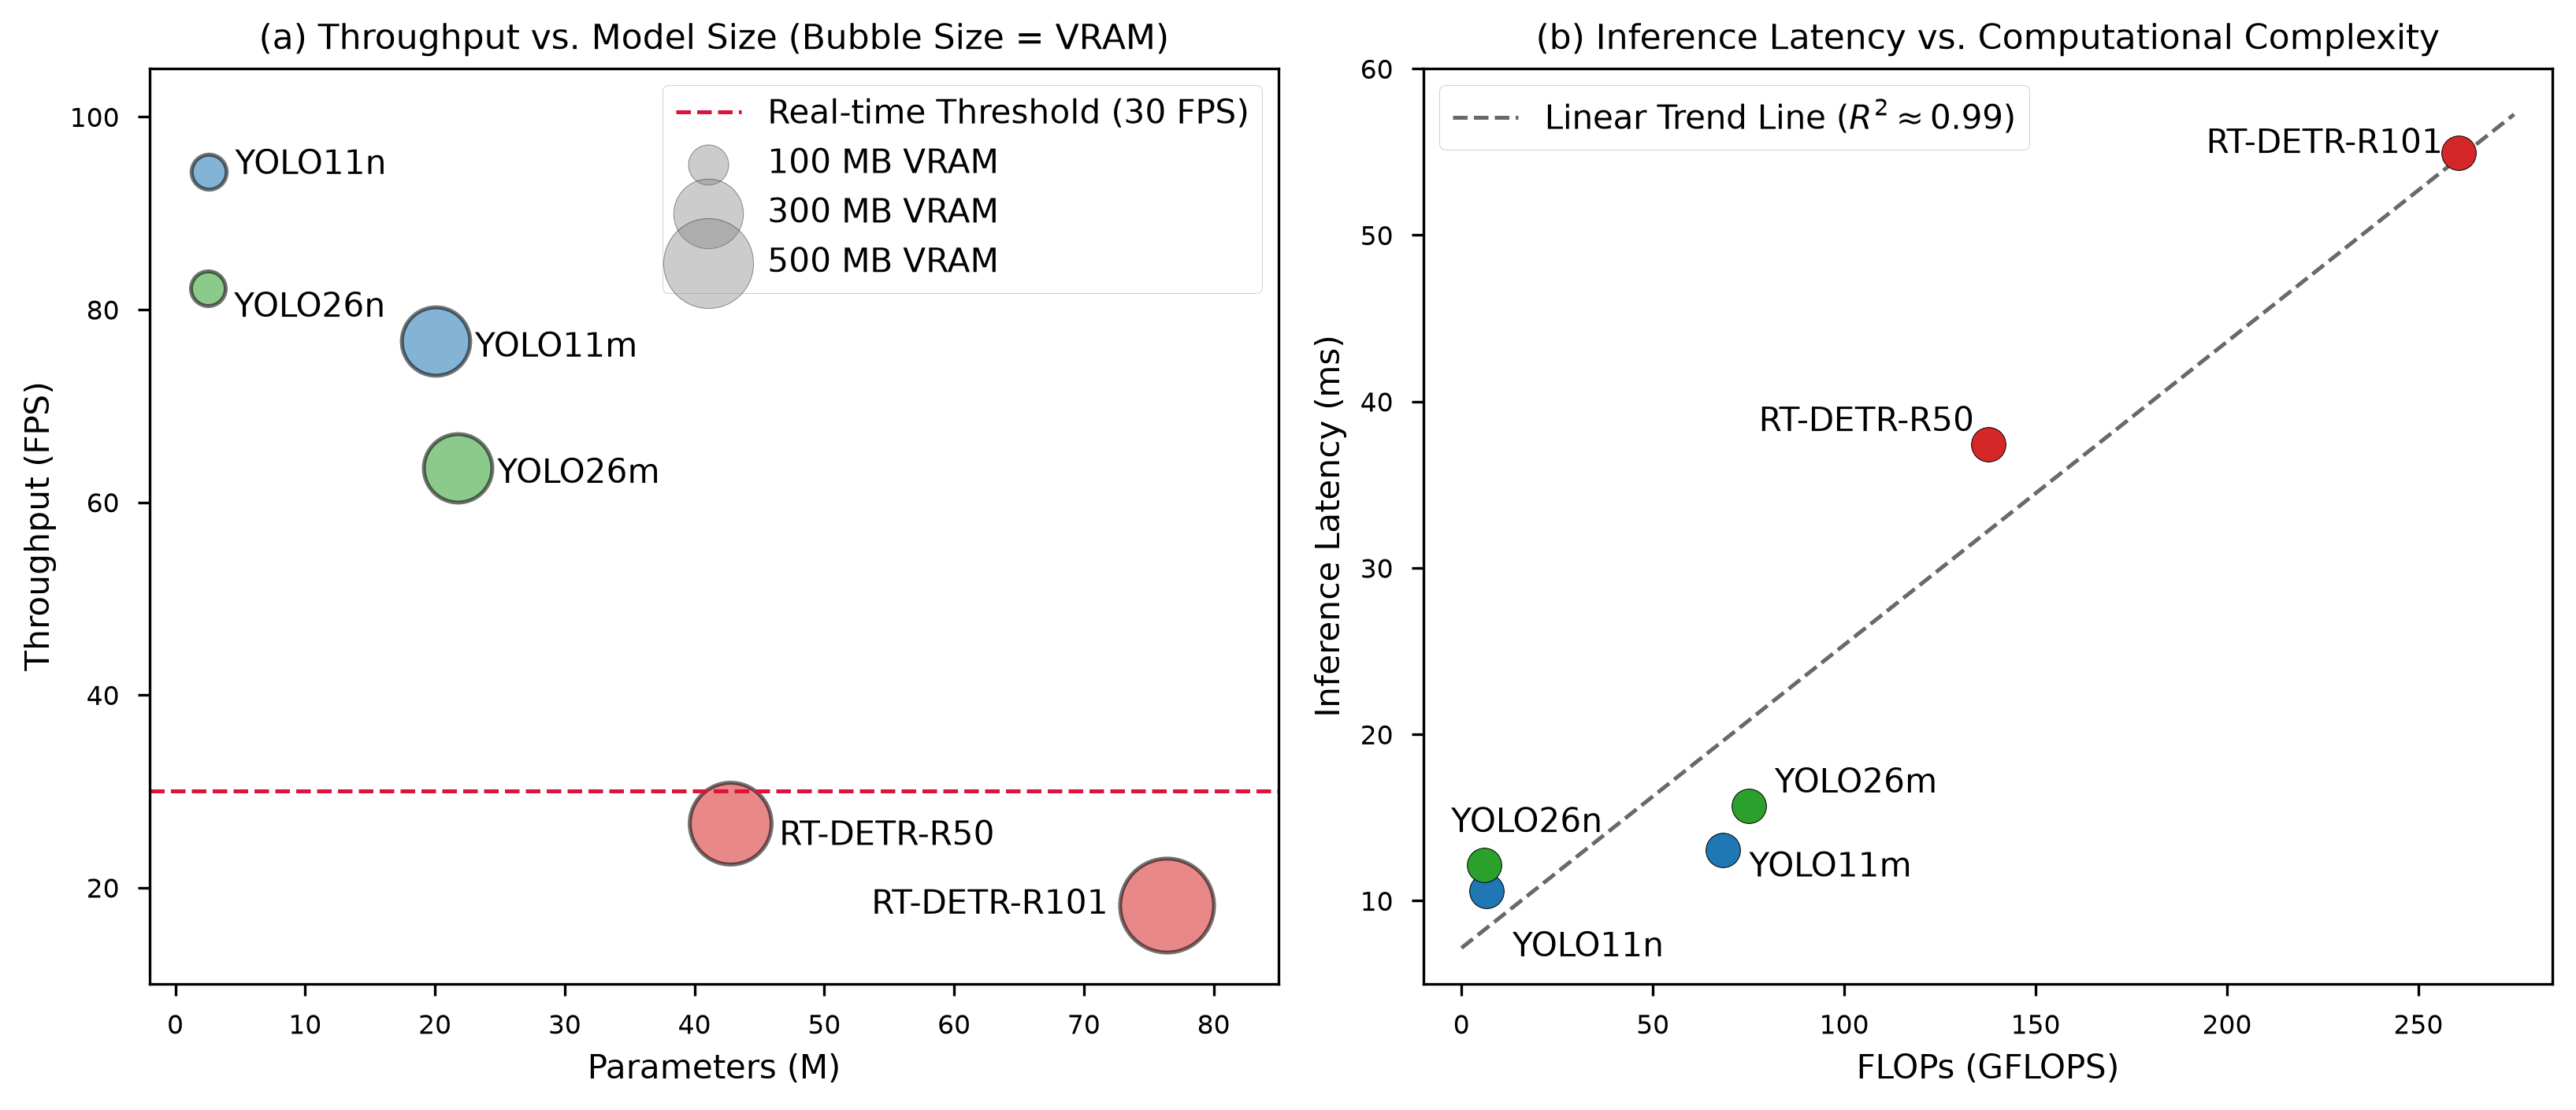

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Dữ liệu từ Table 2 của bài báo
models = ['YOLO11n', 'YOLO11m', 'YOLO26n', 'YOLO26m', 'RT-DETR-R50', 'RT-DETR-R101']
latency = [10.61, 13.04, 12.16, 15.72, 37.44, 54.94]
fps = [94.3, 76.7, 82.2, 63.6, 26.7, 18.2]
gflops = [6.50, 68.32, 5.90, 75.00, 137.72, 260.61]
params = [2.59, 20.06, 2.51, 21.78, 42.74, 76.40]
vram = [75.8, 288.9, 74.5, 289.7, 414.3, 546.1]

# Thiết lập style bài báo IEEE/Springer
plt.style.use('seaborn-v0_8-paper' if 'seaborn-v0_8-paper' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), dpi=300)

# Mẫu màu phân loại họ mô hình: YOLO11 (xanh dương), YOLO26 (xanh lá), RT-DETR (đỏ)
colors = ['#1f77b4', '#1f77b4', '#2ca02c', '#2ca02c', '#d62728', '#d62728']

# =========================================================================
# SUBPLOT (a): BUBBLE CHART (FPS vs. Params, Size = VRAM)
# =========================================================================
sizes = [v * 1.5 for v in vram]  # Tỷ lệ kích thước bóng theo VRAM

# Vị trí nhãn tránh đè nét
offsets_1 = [
    (8, 2),    # YOLO11n
    (12, -2),   # YOLO11m
    (8, -6),   # YOLO26n
    (12, -2),   # YOLO26m
    (15, -4),  # RT-DETR-R50
    (-90, 0)   # RT-DETR-R101
]

for i in range(len(models)):
    ax1.scatter(params[i], fps[i], s=sizes[i], c=colors[i], alpha=0.55, edgecolors='black', linewidth=1.2)
    ax1.annotate(models[i], (params[i], fps[i]), fontsize=10, 
                 xytext=offsets_1[i], textcoords='offset points', va='center')

# Ngưỡng Real-time 30 FPS
ax1.axhline(y=30, color='crimson', linestyle='--', linewidth=1.2, label='Real-time Threshold (30 FPS)')

# Chú thích mẫu kích thước bóng (VRAM Legend)
vram_samples = [100, 300, 500]
for sample in vram_samples:
    ax1.scatter([], [], s=sample*1.5, c='gray', alpha=0.4, edgecolors='black', label=f'{sample} MB VRAM')

ax1.set_xlabel('Parameters (M)', fontsize=10)
ax1.set_ylabel('Throughput (FPS)', fontsize=10)
ax1.set_title('(a) Throughput vs. Model Size (Bubble Size = VRAM)', fontsize=10.5)
ax1.set_ylim(10, 105)
ax1.set_xlim(-2, 85)
ax1.legend(loc='upper right', fontsize=10, frameon=True, framealpha=0.9)

# =========================================================================
# SUBPLOT (b): SCATTER PLOT WITH TREND LINE (Latency vs. GFLOPS)
# =========================================================================
offsets_2 = [
    (8, -20),   # YOLO11n
    (8, -8),   # YOLO11m
    (-10, 10),  # YOLO26n
    (8, 4),    # YOLO26m
    (-70, 4),  # RT-DETR-R50
    (-77, 0)   # RT-DETR-R101
]

for i in range(len(models)):
    ax2.scatter(gflops[i], latency[i], color=colors[i], s=110, edgecolors='black', zorder=5)
    ax2.annotate(models[i], (gflops[i], latency[i]), fontsize=10,
                 xytext=offsets_2[i], textcoords='offset points')

# Đường xu hướng tuyến tính (Linear Fit Line)
z = np.polyfit(gflops, latency, 1)
p = np.poly1d(z)
x_trend = np.linspace(0, 275, 100)
ax2.plot(x_trend, p(x_trend), color='dimgray', linestyle='--', linewidth=1.2, label='Linear Trend Line ($R^2 \\approx 0.99$)')

ax2.set_xlabel('FLOPs (GFLOPS)', fontsize=10)
ax2.set_ylabel('Inference Latency (ms)', fontsize=10)
ax2.set_title('(b) Inference Latency vs. Computational Complexity', fontsize=10.5)
ax2.set_xlim(-10, 285)
ax2.set_ylim(5, 60)
ax2.legend(loc='upper left', fontsize=10, frameon=True, framealpha=0.9)

# Căn chỉnh và lưu file PDF/PNG
plt.tight_layout()
plt.savefig(r'D:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\benchmakring_transmission_line_defect_model\visualization\5_1_resource.png', format='png', bbox_inches='tight', dpi=300)
plt.show()

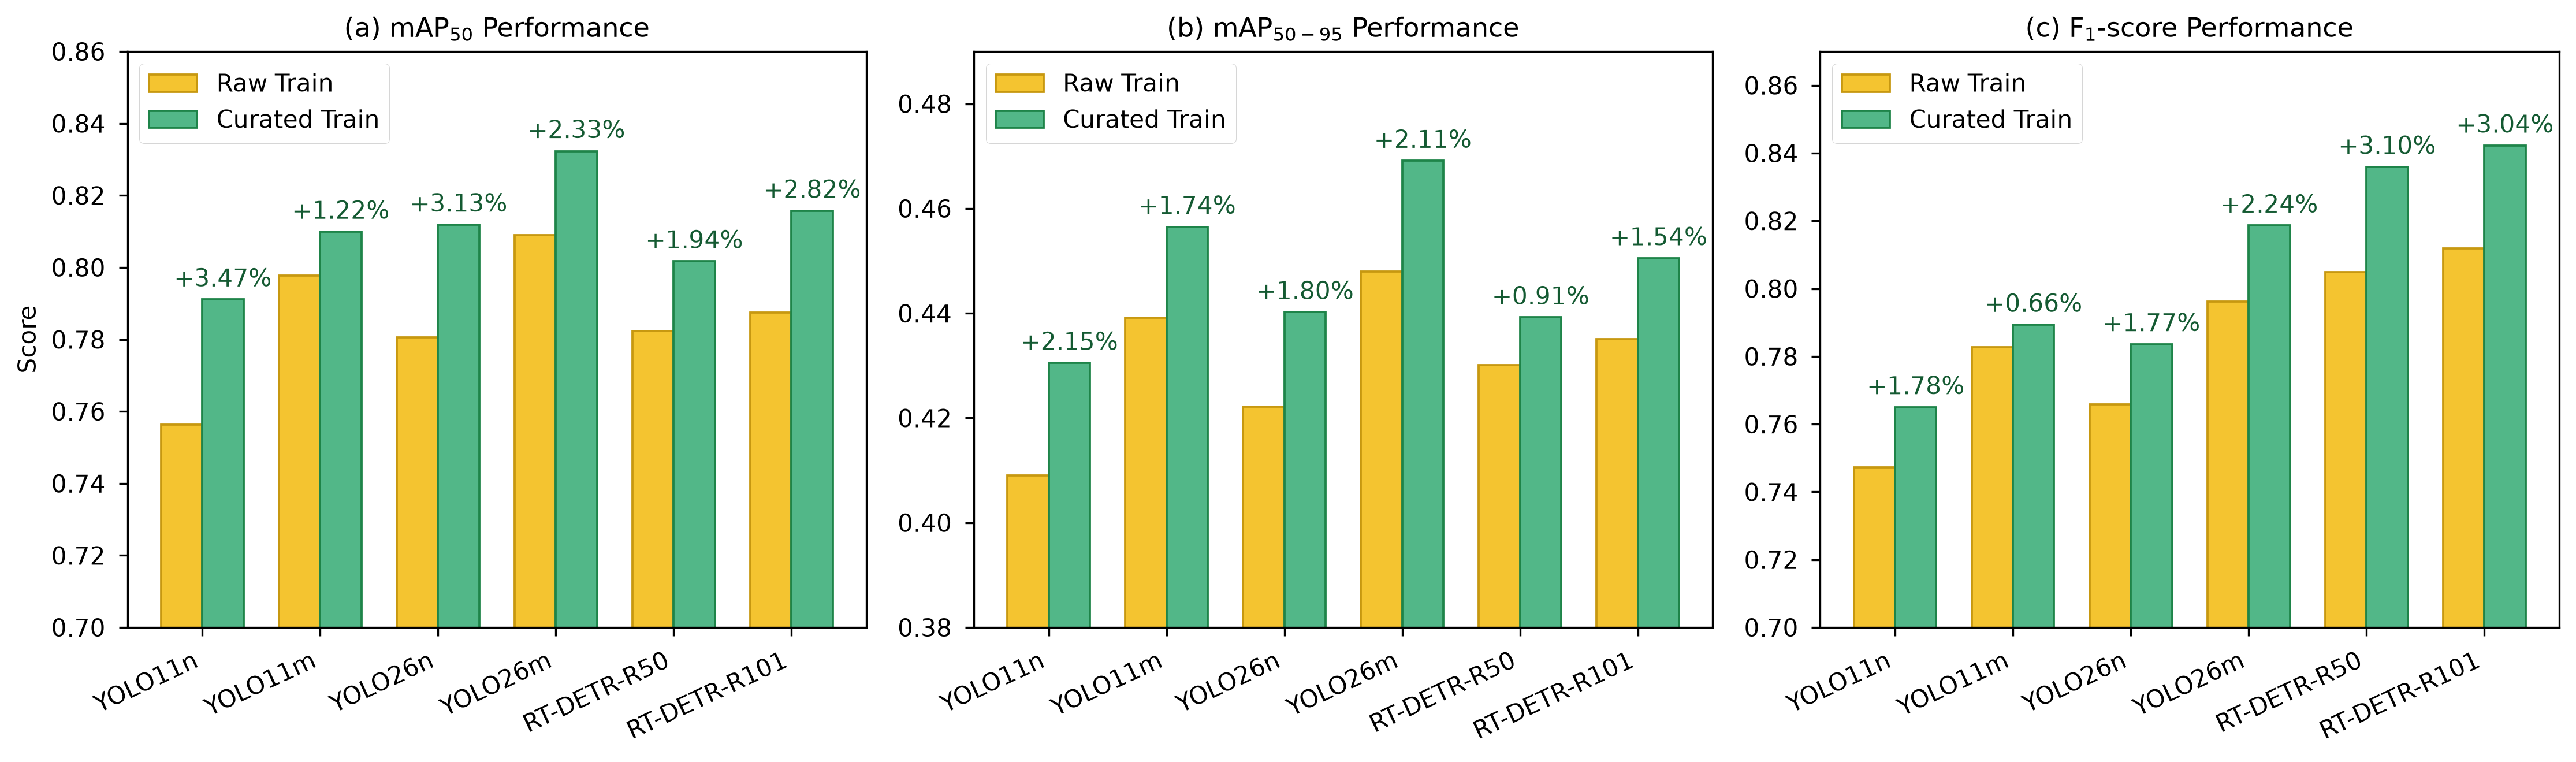

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Dữ liệu từ Table 3
models = ['YOLO11n', 'YOLO11m', 'YOLO26n', 'YOLO26m', 'RT-DETR-R50', 'RT-DETR-R101']

f1_raw = [0.7472, 0.7827, 0.7659, 0.7962, 0.8049, 0.8118]
f1_cur = [0.7650, 0.7893, 0.7836, 0.8186, 0.8359, 0.8422]

map50_raw = [0.7564, 0.7977, 0.7806, 0.8090, 0.7823, 0.7875]
map50_cur = [0.7911, 0.8099, 0.8119, 0.8323, 0.8017, 0.8157]

map5095_raw = [0.4090, 0.4391, 0.4222, 0.4480, 0.4301, 0.4351]
map5095_cur = [0.4305, 0.4565, 0.4402, 0.4691, 0.4392, 0.4505]

x = np.arange(len(models))
width = 0.35

plt.style.use('seaborn-v0_8-paper' if 'seaborn-v0_8-paper' in plt.style.available else 'default')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)

# Tone màu vừa phải (Warm Golden Yellow & Medium Emerald Green)
c_raw = '#F4C430'
c_cur = '#52B788'

# --- SUBPLOT 1: mAP50 ---
ax1.bar(x - width/2, map50_raw, width, label='Raw Train', color=c_raw, edgecolor='#C79810', linewidth=0.9)
ax1.bar(x + width/2, map50_cur, width, label='Curated Train', color=c_cur, edgecolor='#1E8449', linewidth=0.9)
ax1.set_title('(a) $\mathrm{mAP}_{50}$ Performance', fontsize=11 )
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=25, ha='right', fontsize=10)
ax1.set_ylim(0.70, 0.86)
ax1.set_ylabel('Score', fontsize=10)
ax1.legend(fontsize=10, frameon=True)

for i in range(len(models)):
    diff = (map50_cur[i] - map50_raw[i]) * 100
    ax1.annotate(f'+{diff:.2f}%', xy=(x[i] + width/2, map50_cur[i]), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, color='#145A32')

# --- SUBPLOT 2: mAP50-95 ---
ax2.bar(x - width/2, map5095_raw, width, label='Raw Train', color=c_raw, edgecolor='#C79810', linewidth=0.9)
ax2.bar(x + width/2, map5095_cur, width, label='Curated Train', color=c_cur, edgecolor='#1E8449', linewidth=0.9)
ax2.set_title('(b) $\mathrm{mAP}_{50-95}$ Performance', fontsize=11 )
ax2.set_xticks(x)
ax2.set_xticklabels(models, rotation=25, ha='right', fontsize=10)
ax2.set_ylim(0.38, 0.49)
ax2.legend(fontsize=10, frameon=True)

for i in range(len(models)):
    diff = (map5095_cur[i] - map5095_raw[i]) * 100
    ax2.annotate(f'+{diff:.2f}%', xy=(x[i] + width/2, map5095_cur[i]), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, color='#145A32')

# --- SUBPLOT 3: F1-score ---
ax3.bar(x - width/2, f1_raw, width, label='Raw Train', color=c_raw, edgecolor='#C79810', linewidth=0.9)
ax3.bar(x + width/2, f1_cur, width, label='Curated Train', color=c_cur, edgecolor='#1E8449', linewidth=0.9)
ax3.set_title('(c) $\mathrm{F}_1$-score Performance', fontsize=11 )
ax3.set_xticks(x)
ax3.set_xticklabels(models, rotation=25, ha='right', fontsize=10)
ax3.set_ylim(0.70, 0.87)
ax3.legend(fontsize=10, frameon=True)

for i in range(len(models)):
    diff = (f1_cur[i] - f1_raw[i]) * 100
    ax3.annotate(f'+{diff:.2f}%', xy=(x[i] + width/2, f1_cur[i]), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, color='#145A32')

ax1.tick_params(axis='y', labelsize=10)
ax2.tick_params(axis='y', labelsize=10)
ax3.tick_params(axis='y', labelsize=10)

plt.tight_layout()
plt.savefig(r'D:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\benchmakring_transmission_line_defect_model\visualization\5_2_benchmark.png', format='png', bbox_inches='tight', dpi=300)
plt.show()

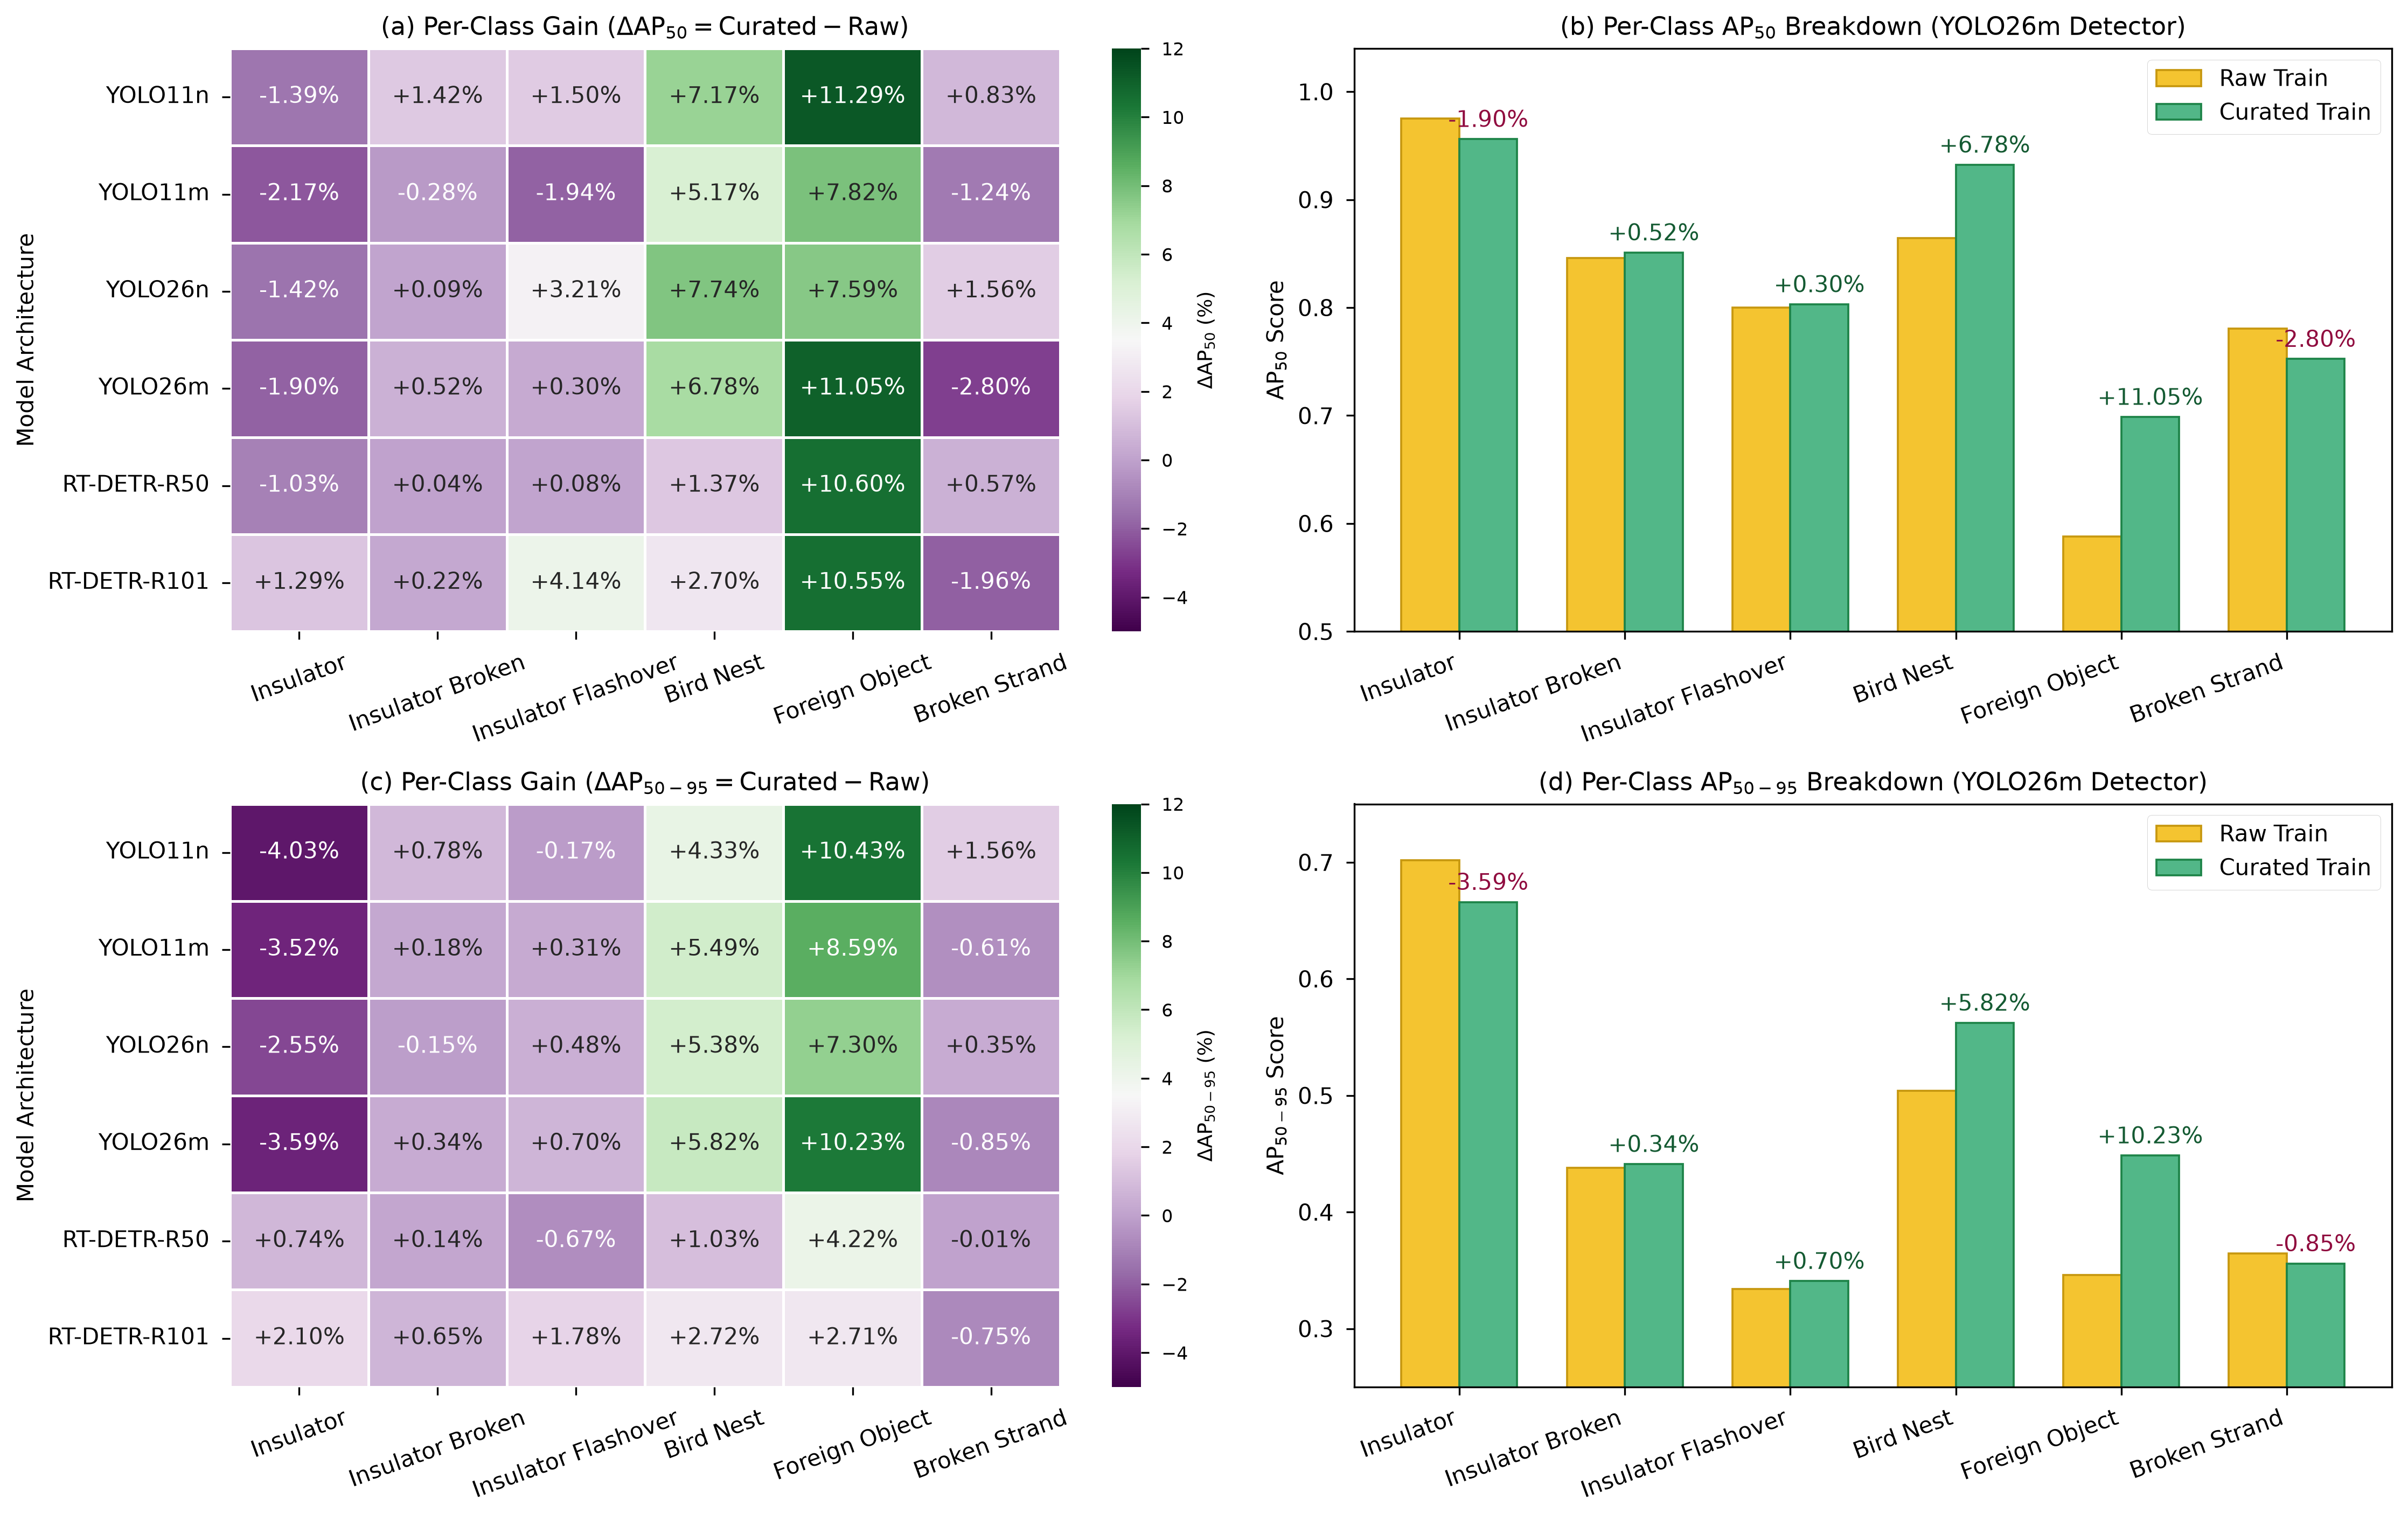

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Danh mục Lớp đối tượng & Mô hình
classes = ['Insulator', 'Insulator Broken', 'Insulator Flashover', 'Bird Nest', 'Foreign Object', 'Broken Strand']
models = ['YOLO11n', 'YOLO11m', 'YOLO26n', 'YOLO26m', 'RT-DETR-R50', 'RT-DETR-R101']

# 2. Dữ liệu AP50 Raw & Curated
ap50_raw = np.array([
    [0.9437, 0.7604, 0.7072, 0.8372, 0.5742, 0.7155], # YOLO11n
    [0.9652, 0.8225, 0.7966, 0.8511, 0.6057, 0.7450], # YOLO11m
    [0.9578, 0.8083, 0.7501, 0.8283, 0.5786, 0.7607], # YOLO26n
    [0.9751, 0.8458, 0.8000, 0.8645, 0.5882, 0.7804], # YOLO26m
    [0.9312, 0.8066, 0.7400, 0.8757, 0.5910, 0.7491], # RT-DETR-R50
    [0.9235, 0.8182, 0.7041, 0.8902, 0.6293, 0.7594]  # RT-DETR-R101
])

ap50_cur = np.array([
    [0.9298, 0.7746, 0.7222, 0.9089, 0.6871, 0.7238], # YOLO11n
    [0.9435, 0.8197, 0.7772, 0.9028, 0.6839, 0.7326], # YOLO11m
    [0.9436, 0.8092, 0.7822, 0.9057, 0.6545, 0.7763], # YOLO26n
    [0.9561, 0.8510, 0.8030, 0.9323, 0.6987, 0.7524], # YOLO26m
    [0.9209, 0.8070, 0.7408, 0.8894, 0.6970, 0.7548], # RT-DETR-R50
    [0.9364, 0.8204, 0.7455, 0.9172, 0.7348, 0.7398]  # RT-DETR-R101
])

# 3. Dữ liệu AP50-95 Raw & Curated
ap5095_raw = np.array([
    [0.6598, 0.3862, 0.2841, 0.4699, 0.3168, 0.3370], # YOLO11n
    [0.6882, 0.4259, 0.3311, 0.4992, 0.3493, 0.3409], # YOLO11m
    [0.6568, 0.4102, 0.3047, 0.4739, 0.3338, 0.3535], # YOLO26n
    [0.7018, 0.4377, 0.3338, 0.5041, 0.3462, 0.3644], # YOLO26m
    [0.6170, 0.4045, 0.3068, 0.5256, 0.3756, 0.3513], # RT-DETR-R50
    [0.6267, 0.4089, 0.2892, 0.5188, 0.4144, 0.3528]  # RT-DETR-R101
])

ap5095_cur = np.array([
    [0.6195, 0.3940, 0.2824, 0.5132, 0.4211, 0.3526], # YOLO11n
    [0.6530, 0.4277, 0.3342, 0.5541, 0.4352, 0.3348], # YOLO11m
    [0.6313, 0.4087, 0.3095, 0.5277, 0.4068, 0.3570], # YOLO26n
    [0.6659, 0.4411, 0.3408, 0.5623, 0.4485, 0.3559], # YOLO26m
    [0.6244, 0.4059, 0.3001, 0.5359, 0.4178, 0.3512], # RT-DETR-R50
    [0.6477, 0.4154, 0.3070, 0.5460, 0.4415, 0.3453]  # RT-DETR-R101
])

# Tính mức chênh lệch Delta (%)
delta_ap50 = (ap50_cur - ap50_raw) * 100
delta_ap5095 = (ap5095_cur - ap5095_raw) * 100

# Tạo ma trận nhãn chuỗi (+X.XX% / -X.XX%)
annot_50 = np.empty_like(delta_ap50, dtype=object)
annot_5095 = np.empty_like(delta_ap5095, dtype=object)

for i in range(len(models)):
    for j in range(len(classes)):
        v50 = delta_ap50[i, j]
        v5095 = delta_ap5095[i, j]
        annot_50[i, j] = f"{'+' if v50 > 0 else ''}{v50:.2f}%"
        annot_5095[i, j] = f"{'+' if v5095 > 0 else ''}{v5095:.2f}%"

# Thiết lập Figure (2x2 Grid)
plt.style.use('seaborn-v0_8-paper' if 'seaborn-v0_8-paper' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), dpi=300)

c_raw = '#F4C430'  # Vàng nghệ ấm
c_cur = '#52B788'  # Xanh ngọc tươi vừa

x = np.arange(len(classes))
width = 0.35

# =========================================================================
# SUBPLOT (a): HEATMAP DELTA AP50
# =========================================================================
sns.heatmap(delta_ap50, annot=annot_50, fmt="", cmap="PRGn", vmin=-5, vmax=12,
            xticklabels=classes, yticklabels=models, ax=axes[0, 0], linewidths=0.8,
            cbar_kws={'label': '$\Delta\mathrm{AP}_{50}$ (%)'})
axes[0, 0].set_title(r"(a) Per-Class Gain ($\Delta\mathrm{AP}_{50} = \mathrm{Curated} - \mathrm{Raw}$)", fontsize=11 )
axes[0, 0].set_ylabel("Model Architecture", fontsize=10 )
axes[0, 0].tick_params(axis='x', rotation=20, labelsize=10)
axes[0, 0].tick_params(axis='y', labelsize=10)

# =========================================================================
# SUBPLOT (b): YOLO26m AP50 BAR CHART
# =========================================================================
axes[0, 1].bar(x - width/2, ap50_raw[3], width, label='Raw Train', color=c_raw, edgecolor='#C79810', linewidth=0.9)
axes[0, 1].bar(x + width/2, ap50_cur[3], width, label='Curated Train', color=c_cur, edgecolor='#1E8449', linewidth=0.9)
axes[0, 1].set_title(r"(b) Per-Class $\mathrm{AP}_{50}$ Breakdown (YOLO26m Detector)", fontsize=11 )
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(classes, rotation=20, ha='right', fontsize=10)
axes[0, 1].set_ylim(0.50, 1.04)
axes[0, 1].tick_params(axis='y', labelsize=10)
axes[0, 1].set_ylabel('$\mathrm{AP}_{50}$ Score', fontsize=10 )
axes[0, 1].legend(fontsize=10, frameon=True)

for i in range(len(classes)):
    diff = delta_ap50[3, i]
    color = '#145A32' if diff >= 0 else '#900C3F'
    sign = "+" if diff >= 0 else ""
    axes[0, 1].annotate(f'{sign}{diff:.2f}%', xy=(x[i] + width/2, ap50_cur[3][i]), xytext=(0, 3),
                        textcoords="offset points", ha='center', va='bottom', fontsize=10 , color=color)

# =========================================================================
# SUBPLOT (c): HEATMAP DELTA AP50-95
# =========================================================================
sns.heatmap(delta_ap5095, annot=annot_5095, fmt="", cmap="PRGn", vmin=-5, vmax=12,
            xticklabels=classes, yticklabels=models, ax=axes[1, 0], linewidths=0.8,
            cbar_kws={'label': '$\Delta\mathrm{AP}_{50-95}$ (%)'})
axes[1, 0].set_title(r"(c) Per-Class Gain ($\Delta\mathrm{AP}_{50-95} = \mathrm{Curated} - \mathrm{Raw}$)", fontsize=11 )
axes[1, 0].set_ylabel("Model Architecture", fontsize=10 )
axes[1, 0].tick_params(axis='x', rotation=20, labelsize=10)
axes[1, 0].tick_params(axis='y', labelsize=10)

# =========================================================================
# SUBPLOT (d): YOLO26m AP50-95 BAR CHART
# =========================================================================
axes[1, 1].bar(x - width/2, ap5095_raw[3], width, label='Raw Train', color=c_raw, edgecolor='#C79810', linewidth=0.9)
axes[1, 1].bar(x + width/2, ap5095_cur[3], width, label='Curated Train', color=c_cur, edgecolor='#1E8449', linewidth=0.9)
axes[1, 1].set_title(r"(d) Per-Class $\mathrm{AP}_{50-95}$ Breakdown (YOLO26m Detector)", fontsize=11 )
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(classes, rotation=20, ha='right', fontsize=10)
axes[1, 1].set_ylim(0.25, 0.75)
axes[1, 1].tick_params(axis='y', labelsize=10)
axes[1, 1].set_ylabel('$\mathrm{AP}_{50-95}$ Score', fontsize=10 )
axes[1, 1].legend(fontsize=10, frameon=True)

for i in range(len(classes)):
    diff = delta_ap5095[3, i]
    color = '#145A32' if diff >= 0 else '#900C3F'
    sign = "+" if diff >= 0 else ""
    axes[1, 1].annotate(f'{sign}{diff:.2f}%', xy=(x[i] + width/2, ap5095_cur[3][i]), xytext=(0, 3),
                        textcoords="offset points", ha='center', va='bottom', fontsize=10 , color=color)

plt.tight_layout()
plt.savefig(r'D:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\benchmakring_transmission_line_defect_model\visualization\5_3_per_class.png', format='png', bbox_inches='tight', dpi=300)
plt.show()